# Семинар 12. NumPy, двумерный массив


In [17]:
import numpy as np

## Создание матриц

In [18]:
I = np.eye(3, dtype=int)    # Единичная матрица
Z = np.zeros((3, 3))        # Нулевая матрица
D = np.diag([2, 5, 7])      # Диагональная матрица
F = np.full((2, 3), 10)     # Матрица заданного размера

print('Единичная матрица')
print(I)
print('Нулевая матрица')
print(Z)
print('Диагональная матрица')
print(D)
print('Матрица заданного размера')
print(F)

Единичная матрица
[[1 0 0]
 [0 1 0]
 [0 0 1]]
Нулевая матрица
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Диагональная матрица
[[2 0 0]
 [0 5 0]
 [0 0 7]]
Матрица заданного размера
[[10 10 10]
 [10 10 10]]


## Индексация и геометрия матрицы
![pic1.jpg](pic1.jpg)
![pic2.jpg](pic2.jpg)

In [19]:
A = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

print(A[1, 2])   # 60
print(A[1, :])    # вторая строка
print(A[:, 0])    # первый столбец
print("подматрица 2x2:")
print(A[:2, :2])
print("Строки 0, 2")
print(A[[0, 2]])

60
[40 50 60]
[10 40 70]
подматрица 2x2:
[[10 20]
 [40 50]]
Строки 0, 2
[[10 20 30]
 [70 80 90]]


## Объединение

- np.vstack() — объединение по вертикали
- np.hstack() — объединение по горизонтали

![stake.jpg](stake.jpg)

## Транспонирование и матричное умножение

In [20]:
A = np.array([[1, 2],
              [3, 4]])

B = np.array([[10, 20],
              [30, 40]])
print("Транспонирование")
print(A.T)

# Матричное умножение
print("Матричное умножение")
print(A @ B)
# или
print("Матричное умножение")
print(np.matmul(A, B))

print("Определитель", np.linalg.det(A))

Транспонирование
[[1 3]
 [2 4]]
Матричное умножение
[[ 70 100]
 [150 220]]
Матричное умножение
[[ 70 100]
 [150 220]]
Определитель -2.0000000000000004


| Математическое понятие | NumPy |
| :--- | :--- |
| Определитель | `np.linalg.det(A)` |
| Ранг | `np.linalg.matrix_rank(A)` |
| Обратная матрица | `np.linalg.inv(A)` |
| След матрицы | `np.trace(A)` |
| Норма | `np.linalg.norm(A)` |
| Собственные значения | `np.linalg.eigvals(A)` |
| Собственные векторы и значения | `np.linalg.eig(A)` |


## Система линейных уравнений
Решить уравнение A*x=b

In [21]:
A = np.array([
    [2, 1, 1],
    [1, 3, 2],
    [3, 2, 4]
], dtype=float)

b = np.array([10, 13, 23], dtype=float)

x = np.linalg.solve(A, b)

print("Решение:", x)
print("Проверка:", A @ x)

Решение: [2.81818182 1.45454545 2.90909091]
Проверка: [10. 13. 23.]


### Аппроксимация экспериментальных данных
$$
\begin{pmatrix}
0 & 1 \\
1 & 1 \\
2 & 1 \\
3 & 1 \\
4 & 1
\end{pmatrix}
\begin{pmatrix}
a \\
b
\end{pmatrix}
\approx
\begin{pmatrix}
1.1 \\
2.9 \\
5.2 \\
6.8 \\
9.1
\end{pmatrix}
$$


In [8]:
### Аппроксимация экспериментальных данных
x_data = np.array([0, 1, 2, 3, 4], dtype=float)
y_data = np.array([1.1, 2.9, 5.2, 6.8, 9.1])

A = np.column_stack((x_data, np.ones_like(x_data)))

coefficients, residuals, rank, s = np.linalg.lstsq(
    A, y_data, rcond=None
)

a, b = coefficients

print("a =", a)
print("b =", b)
print("Остатки =", residuals)

a = 1.99
b = 1.0399999999999987
Остатки = [0.107]


## `reshape`

Те же шесть чисел, что лежали вектором. `shape` теперь два числа: две строки и три столбца. `size` по-прежнему считает элементы и равен 6.


In [9]:
a = np.arange(6).reshape(2, 3)
print(a)
print(a.shape)
print(a.ndim)
print(a.size)


[[0 1 2]
 [3 4 5]]
(2, 3)
2
6


Вложенный список становится матрицей, когда внутренние списки одной длины.

In [ ]:
print(np.array([[0, 1, 2], [3, 4, 5]]))


В массиве 6 элементов, а в форме их 8. `reshape` не выдумывает недостающие числа.


In [22]:
np.arange(6).reshape(4, 2)


ValueError: cannot reshape array of size 6 into shape (4,2)

## Маска и решето

Сравнение даёт массив из `True` и `False` той же длины. Запись `a[a > 0]` оставляет элементы, напротив которых стоит `True`.


In [23]:
a = np.array([1., -2, 0, 4])
print(a[a > 0])


[1. 4.]


In [25]:
a = np.array([1,-1,2],[3,-4,5])
a[a>0]

TypeError: Field elements must be 2- or 3-tuples, got '3'

## Ось

Параметр **axis** указывает ось (измерение) массива, вдоль которой выполняется операция. Его значение начинается с нуля. Для агрегирующих операций, например sum или mean, выбранная ось обычно удаляется из результата. Для объединения массивов, например `concatenate`, axis указывает, вдоль какой оси происходит соединение.

Применяется к `sum`, `mean`, `max`, `min`, `concatenate`, `stack` и другим функциям NumPy.

![axis1.jpg](axis1.jpg)

In [ ]:
M = np.array([[1, 2, 3], [4, 5, 6]])
print(np.sum(M, axis=0))
print(np.sum(M, axis=1))
print(np.mean(M, axis=0))
print(np.mean(M, axis=1))



| Функция | Аналог через `concatenate` | Направление объединения (ось) |
| :--- | :--- | :--- |
| `np.vstack((A, B))` | `np.concatenate((A, B), axis=0)` | Вертикально (по строкам, ось 0) |
| `np.hstack((A, B))` | `np.concatenate((A, B), axis=1)` | Горизонтально (по столбцам, ось 1) |
| `np.dstack((A, B))` | `np.concatenate((A, B), axis=2)` | В глубину (по третьей оси, ось 2) |

## Четыре модуля

`linalg` — линейная алгебра. Только что отсюда взяли `solve`. Документация: [linalg](https://numpy.org/doc/stable/reference/routines.linalg.html).

`polynomial` — многочлены: сложение, умножение, корни. Документация: [polynomial](https://numpy.org/doc/stable/reference/routines.polynomials.html).

`random` — случайные числа и распределения. Документация: [random](https://numpy.org/doc/stable/reference/random/index.html).

`fft` — дискретное преобразование Фурье. Документация: [fft](https://numpy.org/doc/stable/reference/routines.fft.html).


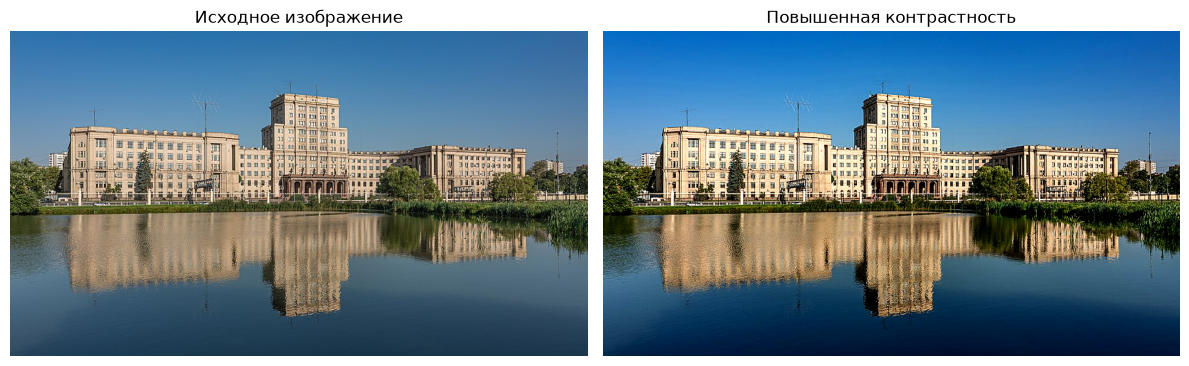

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Читаем изображение
img = Image.open("mgtu.jpg").convert("RGB")

# 2. Преобразуем изображение в NumPy-массив
image = np.array(img)

# 3. Увеличиваем контрастность
factor = 1.50

contrast_image = (image.astype(float) - 127.5) * factor + 127.5

# Ограничиваем значения диапазоном 0..255
contrast_image = np.clip(contrast_image, 0, 255)

# Преобразуем обратно в uint8
contrast_image = contrast_image.astype(np.uint8)

# 4. Отображаем исходное и обработанное изображения
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Исходное изображение")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_image)
plt.title("Повышенная контрастность")
plt.axis("off")

plt.tight_layout()
plt.show()